In [2]:
from perfetto.trace_processor import TraceProcessor
import matplotlib.pyplot as plt

trace_path = "gri_profiled/chemFoam.perfetto-trace"
#trace_path = "orig/gri_profiled/chemFoam.perfetto-trace"

tp = TraceProcessor(trace=trace_path)
df = tp.query("""
  SELECT ts, dur, name
  FROM slice
  WHERE dur > 0
""").as_pandas_dataframe()

print(df.head())

                  ts       dur              name
0  48120459326451788    653787     time controls
1  48120459327218700  40002054  solveChemistry.H
2  48120459327833215   3015485          jacobian
3  48120459331086647   1582150       LUDecompose
4  48120459332674279    435418       derivatives


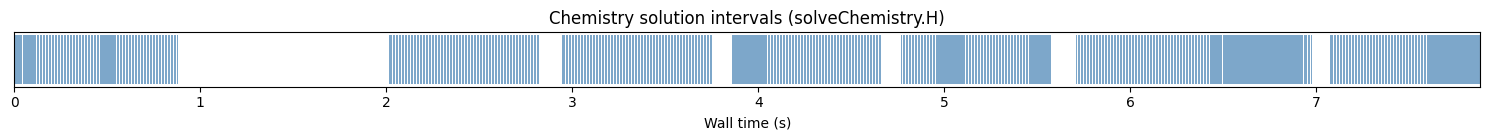

In [3]:
chemistry_df = df[df["name"] == "solveChemistry.H"].copy()
t0 = chemistry_df["ts"].min()
chemistry_df["ts_rel_s"] = (chemistry_df["ts"] - t0) / 1e9
chemistry_df["dur_s"]    = chemistry_df["dur"] / 1e9

fig, ax = plt.subplots(figsize=(15, 1.5))
ax.broken_barh(
    list(zip(chemistry_df["ts_rel_s"], chemistry_df["dur_s"])),
    (0, 1),
    facecolors="steelblue", alpha=0.7
)
ax.set_xlabel("Wall time (s)")
ax.set_yticks([])
ax.set_title("Chemistry solution intervals (solveChemistry.H)")
ax.margins(x=0)
plt.tight_layout()
plt.show()

Chemistry step: 386.41 ms  |  simulation time: 0.059500 s  |  ODE events: 1583
name
derivatives         705
LUBacksubstitute    705
LUDecompose         146
jacobian             27
Name: count, dtype: int64


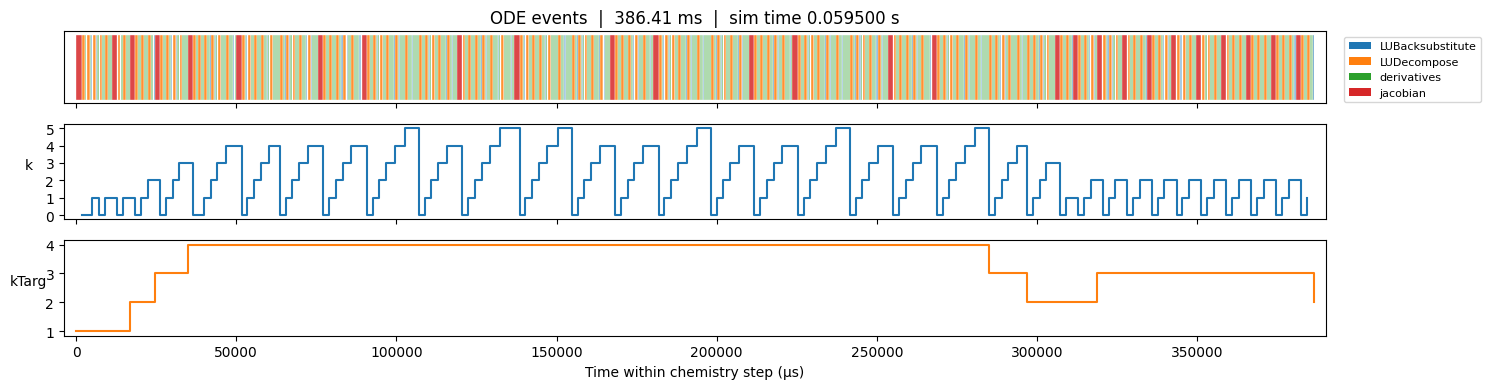

In [4]:
import pandas as pd

# ── User parameter ────────────────────────────────────────────────────
sim_time_query = None   # float in seconds, or None → longest solveChemistry.H step
# ─────────────────────────────────────────────────────────────────────

chemistry_df = df[df["name"] == "solveChemistry.H"].copy()
chemistry_df["ts"]  = chemistry_df["ts"].astype("int64")
chemistry_df["dur"] = chemistry_df["dur"].astype("int64")

# Attach simulation time to each chemistry step via merge_asof
time_counter = tp.query("""
  SELECT c.ts, c.value
  FROM counter c
  JOIN counter_track ct ON c.track_id = ct.id
  WHERE ct.name = 'time'
  ORDER BY c.ts
""").as_pandas_dataframe()
time_counter["ts"] = time_counter["ts"].astype("int64")

chem_sorted = chemistry_df.sort_values("ts").reset_index(drop=True)
merged = pd.merge_asof(
    chem_sorted[["ts", "dur"]],
    time_counter.rename(columns={"value": "sim_time"}),
    on="ts",
    direction="backward",
)

if sim_time_query is None:
    target = merged.loc[merged["dur"].idxmax()]
else:
    target = merged.loc[(merged["sim_time"] - sim_time_query).abs().idxmin()]

ts_start   = int(target["ts"])
ts_end     = ts_start + int(target["dur"])
sim_time_s = float(target["sim_time"])

ode_df = tp.query(f"""
  SELECT ts, dur, name, depth
  FROM slice
  WHERE category = 'ode'
    AND ts >= {ts_start}
    AND ts + dur <= {ts_end}
    AND dur > 0
  ORDER BY ts
""").as_pandas_dataframe()

def fetch_counter(track_name):
    raw = tp.query(f"""
      SELECT c.ts, c.value
      FROM counter c
      JOIN counter_track ct ON c.track_id = ct.id
      WHERE ct.name = '{track_name}'
        AND c.ts >= {ts_start}
        AND c.ts <= {ts_end}
      ORDER BY c.ts
    """).as_pandas_dataframe()
    raw["ts"] = raw["ts"].astype("int64")
    raw["ts_rel_us"] = (raw["ts"] - ts_start) / 1e3
    return raw

k_df     = fetch_counter("seulex.k.current")
ktarg_df = fetch_counter("seulex.kTarg_.current")

print(f"Chemistry step: {target['dur']/1e6:.2f} ms  |  simulation time: {sim_time_s:.6f} s  |  ODE events: {len(ode_df)}")
print(ode_df["name"].value_counts())

ode_df["ts_rel_us"] = (ode_df["ts"].astype("int64") - ts_start) / 1e3
ode_df["dur_us"]    = ode_df["dur"].astype("int64") / 1e3

event_names = sorted(ode_df["name"].unique())
palette     = plt.cm.tab10.colors
name_color  = {n: palette[i % 10] for i, n in enumerate(event_names)}
n_depths    = int(ode_df["depth"].max()) + 1

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, (max(4, n_depths * 1.5) + 4)*0.5),
    gridspec_kw={"height_ratios": [max(2, n_depths * 1.5)/10, 0.4, 0.4]},
    sharex=True,
)

# ── top: ODE event Gantt ──────────────────────────────────────────────
ax = axes[0]
for _, row in ode_df.iterrows():
    ax.broken_barh(
        [(row["ts_rel_us"], max(row["dur_us"], 0.01))],
        (row["depth"] * 1.2, 1.0),
        facecolors=name_color[row["name"]], alpha=0.85,
        edgecolors="white", linewidth=0.3,
    )
from matplotlib.patches import Patch
ax.legend(
    handles=[Patch(facecolor=name_color[n], label=n) for n in event_names],
    bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8,
)
ax.set_yticks([])
ax.set_title(f"ODE events  |  {target['dur']/1e6:.2f} ms  |  sim time {sim_time_s:.6f} s")
ax.margins(x=0.01)

# ── middle: k ────────────────────────────────────────────────────────
ax = axes[1]
if not k_df.empty:
    ax.step(k_df["ts_rel_us"], k_df["value"], where="post", color="tab:blue")
ax.set_ylabel("k", rotation=0, labelpad=12)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.margins(x=0.01)

# ── bottom: kTarg_ ───────────────────────────────────────────────────
ax = axes[2]
if not ktarg_df.empty:
    ax.step(ktarg_df["ts_rel_us"], ktarg_df["value"], where="post", color="tab:orange")
ax.set_ylabel("kTarg", rotation=0, labelpad=12)
ax.set_xlabel("Time within chemistry step (µs)")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.margins(x=0.01)

plt.tight_layout()
plt.show()
